# Lab 04 — Invoice to JSON

Narxoz University · Canvas Assignment 4

Работа выполнена локально на Intel CPU с OpenVINO. Основной опыт: 48 изображений;
дополнительный: 16 казахских изображений с инструкцией сохранять буквы.
Использован квантизованный экспорт Qwen2-VL-2B-Instruct: INT4/INT8 веса и FP32 вычисления CPU;
этот результат не подменяет float16-эталон преподавателя.

Все значения ниже получены из сохранённых исходных ответов собственного прогона.
При исполнении для сдачи ноутбук явно читает эти ответы из cache и заново вычисляет таблицы;
он не заявляет, что тяжёлый VLM-прогон был повторён в каждой ячейке.
Модель, ревизия, версии, время и точность приведены в Part 3 и в отчёте.

## Setup

Этот сохранённый запуск выполнен на **Intel Core i5-1235U, OpenVINO CPU**.
Для просмотра фактических выводов достаточно открыть ноутбук. Для пересчёта таблиц
в проверенном окружении выберите .tools/intel-venv/Scripts/python.exe как kernel;
ячейки загрузят завершённые измерения из 
esults/intel/ без нового вызова модели.

Для нового полного локального прогона используйте 
un_intel.py --device CPU --all --letters:
он сохраняет каждый ответ и продолжает с последнего готового изображения после сбоя.
На этой Iris Xe режим AUTO также выбирает проверенный CPU; GPU с данным драйвером
не прошла контроль. Веса INT4/INT8 отличаются от float16-эталона.

Для независимого прогона в Colab: Runtime → Change runtime type → T4 GPU,
затем исполняйте ячейки по порядку. Первая ячейка установит Tesseract и зависимости.
Для новых слепых прогнозов запишите ответы до раскрытия результатов.


In [1]:
# Colab setup. Local runs may use an already installed Tesseract.
import platform
import shutil
import subprocess
import sys

if 'google.colab' in sys.modules:
    subprocess.run(['apt-get', '-qq', 'update'], check=True)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'tesseract-ocr',
                    'tesseract-ocr-kaz', 'tesseract-ocr-rus'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install',
                    'pytesseract==0.3.13', 'transformers==5.18.0',
                    'accelerate==1.15.0'], check=True)

import pytesseract
from pathlib import Path
local_tesseract = Path('.tools/tesseract/tesseract.exe')
if local_tesseract.is_file():
    import ctypes, os
    short_path = ctypes.create_unicode_buffer(32768)
    if not ctypes.windll.kernel32.GetShortPathNameW(str(local_tesseract.resolve()), short_path, len(short_path)):
        raise OSError('Cannot resolve the local Tesseract path')
    pytesseract.pytesseract.tesseract_cmd = short_path.value
    os.environ['TESSDATA_PREFIX'] = str(Path(short_path.value).parent / 'tessdata')
elif not shutil.which('tesseract'):
    raise RuntimeError('Tesseract is missing. Use the Colab T4 setup above.')
langs = set(pytesseract.get_languages())
assert {'kaz', 'rus', 'eng'} <= langs, f'Missing OCR languages: {langs}'
print('Tesseract:', pytesseract.get_tesseract_version())
print('OCR languages:', sorted(langs))
print('Python:', platform.python_version())

Tesseract: 5.5.3.20260724
OCR languages: ['eng', 'kaz', 'osd', 'rus']
Python: 3.13.2


## Part 0 -- the data and the toolbox

The next cell fetches the 48 images (24 invoices, each clean and degraded) and their
answer files from the lab's GitHub repository. `truth/*.json` says what each invoice
*really* contains; the models never see it. The cell after it is the toolbox: read it,
you will use every function in it, but you do not need to edit anything.

In [2]:
import json
import os
import subprocess

REPO_URL = "https://github.com/unreal-kz/lab-04-AI-course.git"
if not os.path.exists("data/manifest.json"):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    os.chdir("lab-04-AI-course")


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


DOCS = load_json("data/manifest.json")["docs"]
TRUTH = {d["id"]: load_json(f"data/truth/{d['id']}.json") for d in DOCS}
CONDITIONS = ("clean", "degraded")


def image_path(doc, cond):
    return f"data/{cond}/{doc['id']}." + ("png" if cond == "clean" else "jpg")


print(len(DOCS), "documents x", len(CONDITIONS), "conditions =", len(DOCS) * len(CONDITIONS), "images")
print("languages:", sorted({d["lang"] for d in DOCS}))

24 documents x 2 conditions = 48 images
languages: ['en', 'kk', 'ru']


In [3]:
"""Toolbox for Lab 04 -- Invoice to JSON.

This file is the single source of truth for the lab's logic. ``build_notebook.py`` pastes it
verbatim into one notebook cell, and ``reference_run.py`` imports it, so the numbers in the
README come from the same code a student runs. Heavy imports (torch, transformers,
pytesseract) happen inside the functions that need them.
"""

from __future__ import annotations

import difflib
import json
import math
import re
import unicodedata
from collections import Counter
from datetime import date
from typing import Any

MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"
OCR_LANGS = "kaz+rus+eng"
OCR_PSM = 4  # Tesseract page-segmentation mode: "a single column of text of variable sizes"

# Field names only. No value from any truth file ever reaches a prompt.
PROMPT = (
    "Extract this invoice as JSON with exactly these keys: invoice_number, date (YYYY-MM-DD), "
    "seller_name, seller_bin, buyer_name, items (list of objects with name, qty, unit_price, "
    "amount), total. Numbers must be plain integers. Output JSON only."
)

NUMERIC_FIELDS = ("qty", "unit_price", "amount", "total")
NAME_FIELDS = ("seller_name", "buyer_name", "name")  # "name" = an item name
KAZAKH_FOLD = str.maketrans("ӘәҒғҚқҢңӨөҰұҮүҺһІі", "АаГгКкНнОоУуУуХхИи")
LOOKALIKE_FOLD = str.maketrans("ABCEHKMOPTXYaceopxy", "АВСЕНКМОРТХУасеорху")  # Latin -> identical-looking Cyrillic


# ----------------------------------------------------------------------------- parsing
def parse_model_json(text: str) -> dict[str, Any] | None:
    """Parse a model answer into a dict, tolerating a markdown code fence around it.

    Args:
        text: Raw model output.

    Returns:
        The parsed JSON object, or ``None`` if no JSON object can be recovered.
    """
    body = text.strip()
    body = re.sub(r"^```(?:json)?\s*", "", body)
    body = re.sub(r"\s*```$", "", body)
    for candidate in (body, body[body.find("{"): body.rfind("}") + 1]):
        try:
            value = json.loads(candidate)
        except json.JSONDecodeError:
            continue
        if isinstance(value, dict):
            return value
    return None


def flatten(obj: Any, prefix: str = "") -> dict[str, Any]:
    """Flatten nested dicts and lists into ``{"items.0.qty": 40, ...}``."""
    out: dict[str, Any] = {}
    if isinstance(obj, dict):
        for key, value in obj.items():
            out.update(flatten(value, f"{prefix}{key}."))
    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            out.update(flatten(value, f"{prefix}{i}."))
    else:
        out[prefix.rstrip(".")] = obj
    return out


def leaf(path: str) -> str:
    """Last component of a flattened path: ``items.0.qty`` -> ``qty``."""
    return path.rsplit(".", 1)[-1]


# ----------------------------------------------------------------------------- normalisation
def normalize_date(value: Any) -> Any:
    """Turn ``DD.MM.YYYY``, ``DD/MM/YYYY`` or ``DD-MM-YYYY`` into ISO ``YYYY-MM-DD``.

    Anything else (including an already ISO date) is returned stripped and unchanged.
    """
    if not isinstance(value, str):
        return value
    text = value.strip()
    match = re.fullmatch(r"(\d{1,2})[./-](\d{1,2})[./-](\d{4})", text)
    if match:
        day, month, year = (int(g) for g in match.groups())
        try:
            return date(year, month, day).isoformat()
        except ValueError:  # e.g. 31.02.2026: not a real date, leave it for the comparison to fail
            return text
    return text


def normalize_number(value: Any) -> Any:
    """Read ``1 509 000``, ``"1509000"`` or ``1509000.0`` as the integer 1509000.

    Every non-digit character is dropped, so this is deliberately forgiving.
    Returns the input unchanged when no digit is present.
    """
    if isinstance(value, bool):
        return value
    if isinstance(value, int):
        return value
    if isinstance(value, float) and value.is_integer():
        return int(value)
    if isinstance(value, str):
        digits = re.sub(r"\D", "", value)
        if digits:
            return int(digits)
    return value


def normalize_text(value: Any) -> Any:
    """NFC-normalise, collapse whitespace and strip. Case and Kazakh letters are kept."""
    if not isinstance(value, str):
        return value
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", value)).strip()


def normalize_field(path: str, value: Any) -> Any:
    """Apply the normaliser that matches the field at ``path``."""
    name = leaf(path)
    if name == "date":
        return normalize_date(value)
    if name in NUMERIC_FIELDS:
        return normalize_number(value)
    return normalize_text(value)


# ----------------------------------------------------------------------------- scoring
def score_fields(truth: dict[str, Any], pred: dict[str, Any] | None, *,
                 normalized: bool = True) -> dict[str, bool]:
    """Field-level exact match of a prediction against the truth.

    Every field in the truth is scored; a missing field or a missing row counts as wrong, an
    extra row in the prediction is ignored. ``normalized=False`` compares raw JSON values.

    Args:
        truth: Ground-truth invoice.
        pred: Parsed model answer, or ``None`` when parsing failed (every field is wrong).
        normalized: Apply ``normalize_field`` to both sides before comparing.

    Returns:
        ``{flattened path: matched}`` for every field of the truth.
    """
    truth_flat = flatten(truth)
    pred_flat = flatten(pred) if pred is not None else {}
    hits: dict[str, bool] = {}
    for path, expected in truth_flat.items():
        got = pred_flat.get(path)
        if normalized:
            expected, got = normalize_field(path, expected), normalize_field(path, got)
        hits[path] = got == expected
    return hits


def arithmetic_checks(pred: dict[str, Any] | None) -> dict[str, bool]:
    """The two checks of Lecture 5.1: qty x price = amount per row, and sum of amounts = total.

    These use only the prediction, never the truth, so they can run in production.
    Unreadable numbers make the check fail.
    """
    if pred is None:
        return {"rows_ok": False, "total_ok": False}
    items = pred.get("items")
    rows_ok, amounts = isinstance(items, list) and len(items) > 0, []
    for item in items if isinstance(items, list) else []:
        if not isinstance(item, dict):
            rows_ok = False
            continue
        qty, price, amount = (normalize_number(item.get(k)) for k in ("qty", "unit_price", "amount"))
        if not all(isinstance(v, int) and not isinstance(v, bool) for v in (qty, price, amount)):
            rows_ok = False
            continue
        amounts.append(amount)
        rows_ok = rows_ok and qty * price == amount
    total = normalize_number(pred.get("total"))
    total_ok = isinstance(total, int) and not isinstance(total, bool) and len(amounts) > 0 and sum(amounts) == total
    return {"rows_ok": bool(rows_ok), "total_ok": bool(total_ok)}


def wilson(successes: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """Wilson score interval for a proportion (95 % for ``z=1.96``).

    Unlike the plain ``p +- 1.96 * sqrt(p(1-p)/n)`` it stays inside [0, 1] and does not collapse
    to zero width when every trial succeeded: 18/18 gives about (0.82, 1.00).
    """
    if n == 0:
        return (0.0, 1.0)
    p = successes / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


# ----------------------------------------------------------------------------- OCR side
def ocr_text(image_path: str, psm: int = OCR_PSM) -> str:
    """Tesseract OCR with Kazakh, Russian and English models.

    Args:
        image_path: Path to the invoice image.
        psm: Tesseract page-segmentation mode. The default (4) reads a ruled table row by row;
            mode 6 treats the page as one block and loses most of the table.
    """
    import pytesseract

    # A path, not a PIL image: pytesseract re-encodes a PIL JPEG (quality 75) before OCR,
    # which would add a second round of compression to the degraded scans.
    return pytesseract.image_to_string(str(image_path), lang=OCR_LANGS, config=f"--psm {psm}")


def _squash(text: str) -> str:
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", text)).strip().casefold()


def ocr_found(truth: dict[str, Any], text: str) -> dict[str, bool]:
    """For every truth field: does its value appear in the OCR text at all?

    This is an upper bound for any rule-based parser sitting on top of that OCR text: a field
    that is not in the text cannot be extracted from it. It is not a parse, and a number can
    match by accident (``40`` also occurs inside other numbers' neighbourhoods), so treat small
    differences with care.

    Args:
        truth: Ground-truth invoice.
        text: OCR output for the same image.

    Returns:
        ``{flattened path: found}``.
    """
    squashed = _squash(text)
    found: dict[str, bool] = {}
    for path, value in flatten(truth).items():
        name = leaf(path)
        if name in NUMERIC_FIELDS:
            groups = f"{int(value):,}".split(",")  # 580000 -> ["580", "000"]: found as "580 000" or "580000"
            pattern = r"(?<!\d)" + r"[\s ]?".join(groups) + r"(?!\d)"
            found[path] = re.search(pattern, text) is not None
        elif name == "date":
            shown = date.fromisoformat(str(value)).strftime("%d.%m.%Y")
            found[path] = shown in text
        elif name == "seller_bin":
            found[path] = re.search(rf"(?<!\d){value}(?!\d)", text) is not None
        else:
            found[path] = _squash(str(value)) in squashed
    return found


# ----------------------------------------------------------------------------- VLM side
def pick_device() -> str:
    """Pick an available PyTorch device: CUDA, Intel XPU, Apple MPS, or CPU.

    Intel GPUs without PyTorch XPU support can use the separate OpenVINO runner.
    """
    import torch

    if torch.cuda.is_available():
        return "cuda"
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return "xpu"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def load_vlm(device: str | None = None) -> tuple[Any, Any, str]:
    """Load Qwen2-VL-2B-Instruct in eval mode: float16 on a GPU, float32 on CPU.

    Returns:
        ``(model, processor, device)``.
    """
    import torch
    from transformers import AutoProcessor, Qwen2VLForConditionalGeneration

    device = device or pick_device()
    dtype = torch.float32 if device == "cpu" else torch.float16
    model = Qwen2VLForConditionalGeneration.from_pretrained(MODEL_ID, dtype=dtype).to(device)
    model.eval()
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    return model, processor, device


def vlm_extract(model: Any, processor: Any, image_path: str, *, prompt: str = PROMPT,
                hint: str | None = None, max_new_tokens: int = 512) -> str:
    """Ask the VLM to read one invoice image. Greedy decoding, so the answer is repeatable.

    Args:
        model: Model from ``load_vlm``.
        processor: Processor from ``load_vlm``.
        image_path: Path to the invoice image.
        prompt: Instruction text.
        hint: Optional OCR text appended to the prompt (the hybrid experiment).
        max_new_tokens: Generation budget.

    Returns:
        The raw decoded answer, before any JSON parsing.
    """
    text = prompt if hint is None else f"{prompt}\n\nOCR text of the same image (may contain errors):\n{hint}"
    if getattr(model, "backend", None) == "openvino":
        return model.extract(image_path, prompt=text, max_new_tokens=max_new_tokens)

    import torch
    from PIL import Image

    with Image.open(image_path) as img:
        messages = [{"role": "user", "content": [{"type": "image", "image": img.convert("RGB")},
                                                    {"type": "text", "text": text}]}]
        inputs = processor.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt"
        ).to(model.device)
    with torch.inference_mode():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_ids = out[0][inputs["input_ids"].shape[1]:]
    return processor.decode(new_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)


# ----------------------------------------------------------------------------- error analysis
def fold_kazakh(text: str) -> str:
    """Replace each Kazakh-specific letter with its nearest plain Cyrillic one (Қ->К, Ә->А, ...)."""
    return text.translate(KAZAKH_FOLD)


def fold_lookalikes(text: str) -> str:
    """Replace Latin letters that look identical to Cyrillic ones (T, O, A, ...) with the Cyrillic letter."""
    return text.translate(LOOKALIKE_FOLD)


def error_kind(truth_text: str, pred_text: Any) -> str:
    """Why is a name wrong? The first kind that explains it, checked in this order.

    * ``missing``: the model returned no string at all
    * ``script``: the same text once Latin look-alike letters are mapped to Cyrillic
      (``TOO`` typed with Latin letters instead of ``ТОО``)
    * ``kazakh``: the same text once Kazakh-specific letters are mapped to plain Cyrillic
    * ``both``: needs both foldings
    * ``misread``: still different, a genuine reading error or invented text
    """
    if not isinstance(pred_text, str):
        return "missing"
    if truth_text == pred_text:
        return "equal"
    if fold_lookalikes(truth_text) == fold_lookalikes(pred_text):
        return "script"
    if fold_kazakh(truth_text) == fold_kazakh(pred_text):
        return "kazakh"
    if fold_lookalikes(fold_kazakh(truth_text)) == fold_lookalikes(fold_kazakh(pred_text)):
        return "both"
    return "misread"


def char_confusions(truth_text: str, pred_text: str) -> Counter[tuple[str, str]]:
    """Count (true char, read char) pairs where the two strings differ by same-length replacement."""
    pairs: Counter[tuple[str, str]] = Counter()
    matcher = difflib.SequenceMatcher(None, truth_text, pred_text, autojunk=False)
    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        if tag == "replace" and i2 - i1 == j2 - j1:
            pairs.update(zip(truth_text[i1:i2], pred_text[j1:j2]))
    return pairs

In [4]:
"""Atomic, validated checkpoints and a single-process lock for the long CPU run."""

from contextlib import contextmanager
import json
import os
from pathlib import Path

from lab04_core import PROMPT, arithmetic_checks, parse_model_json, score_fields

LETTER_PROMPT = PROMPT + ' ' + (
    'Copy every name letter by letter, exactly as printed. The text may contain the Kazakh '
    'letters ә ғ қ ң ө ұ ү һ і: do not replace them with Russian letters.'
)


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    with temporary.open('w', encoding='utf-8', newline='\n') as stream:
        json.dump(value, stream, ensure_ascii=False, indent=2)
        stream.write('\n')
        stream.flush()
        os.fsync(stream.fileno())
    temporary.replace(path)


@contextmanager
def run_lock(path=Path('.tools/lab04-inference.lock')):
    """The OS releases the lock even after a crash; do not delete lock files."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('a+b') as stream:
        stream.seek(0, 2)
        if stream.tell() == 0:
            stream.write(b'0')
            stream.flush()
        stream.seek(0)
        try:
            if os.name == 'nt':
                import msvcrt
                msvcrt.locking(stream.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(stream, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except OSError as exc:
            raise RuntimeError('Another Lab 04 inference process holds the lock.') from exc
        try:
            yield
        finally:
            stream.seek(0)
            if os.name == 'nt':
                msvcrt.locking(stream.fileno(), msvcrt.LK_UNLCK, 1)
            else:
                fcntl.flock(stream, fcntl.LOCK_UN)


def score_record(doc_id, condition, raw, truth, **metadata):
    pred = parse_model_json(raw)
    return dict(metadata, doc_id=doc_id, condition=condition, raw=raw, pred=pred,
                strict=score_fields(truth, pred, normalized=False),
                norm=score_fields(truth, pred), arith=arithmetic_checks(pred))


def load_records(path, truths, expected=None):
    path = Path(path)
    if not path.exists():
        return {}
    rows = json.loads(path.read_text(encoding='utf-8'))
    result = {}
    for row in rows:
        key = row['doc_id'], row['condition']
        if key in result or (expected is not None and key not in expected):
            raise ValueError(f'Duplicate or unexpected checkpoint key: {key}')
        scored = score_record(*key, row['raw'], truths[key[0]])
        for metric in ('pred', 'strict', 'norm', 'arith'):
            if row.get(metric) != scored[metric]:
                raise ValueError(f'Checkpoint has inconsistent {metric}: {key}')
        result[key] = row
    return result


def recover_raw(raw_dir, records, truths, expected, prompt, manifest):
    """Recover a finished generation if scoring/checkpointing was interrupted."""
    import hashlib

    expected_hashes = {d['id']: d['sha256'] for d in manifest['docs']}
    for path in sorted(Path(raw_dir).glob('*.json')):
        row = json.loads(path.read_text(encoding='utf-8'))
        key = row['doc_id'], row['condition']
        if key not in expected or key in records:
            continue
        if row['prompt'] != prompt or row['image_sha256'] != expected_hashes[key[0]][key[1]]:
            raise ValueError(f'Raw journal configuration mismatch: {path}')
        records[key] = score_record(*key, row['raw'], truths[key[0]],
            seconds=row['seconds'], device='CPU', image_sha256=row['image_sha256'],
            prompt_sha256=hashlib.sha256(prompt.encode()).hexdigest(),
            finished_at_utc=row['finished_at_utc'], recovered_from_raw=True)
    return records


## Part 1 -- look before you measure

Eight invoices, each written in Kazakh (`kk`), Russian (`ru`) and English (`en`), each
as a clean render and as a degraded copy (40 % of the resolution, tilted, blurred, heavy
JPEG). Below: the first invoice's truth and both pictures.

inv01_kk truth (first lines):
{
 "invoice_number": "8043",
 "date": "2026-09-29",
 "seller_name": "«Нарынқол Трейд» ЖШС",
 "seller_bin": "101030509027",
 "buyer_name": "«Арай Маркет» ЖШС",
 "items": [
  {
   "name": "Жұмыртқа, 30 дана",
   "qty": 145,
   "unit_price": 1950,
   "amount": 282750
  },
  {
   "name": "Ірімшік, 1 кг",
   "qty": 90,
   "unit_price": 3850,
   "amount": 346500
  },
  {
   "name": "Күнбағыс майы, 5 л",
   "qty": 95,
   "unit_price": 3250,
   "amount": 308750
  },
  {
   "name": "Күріш, 25 кг",
   "qt ...
clean (1100, 760)


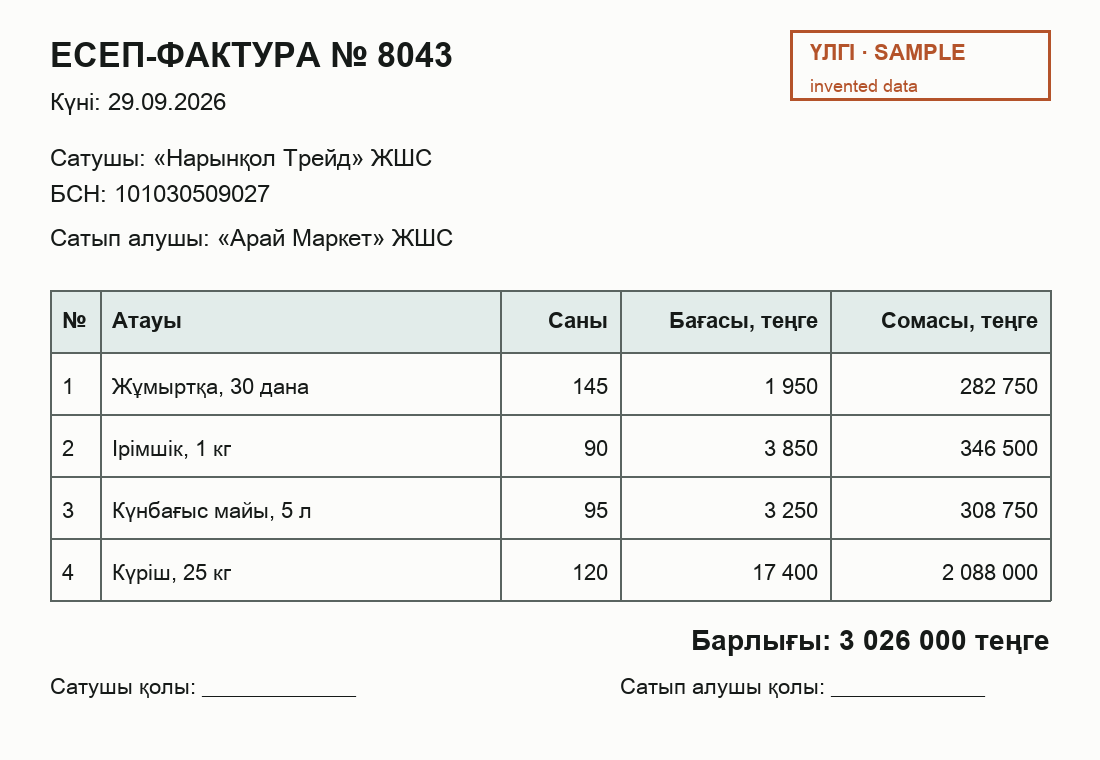

degraded (452, 320)


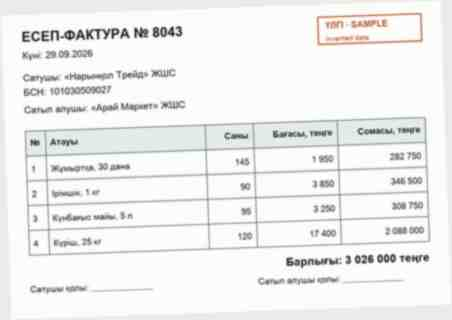

In [5]:
from PIL import Image

try:
    from IPython.display import display
except ImportError:  # running outside a notebook
    display = print

doc = DOCS[0]
print(doc["id"], "truth (first lines):")
print(json.dumps(TRUTH[doc["id"]], ensure_ascii=False, indent=1)[:500], "...")
for cond in CONDITIONS:
    with Image.open(image_path(doc, cond)) as im:
        print(cond, im.size)
        display(im.copy())

✏️ **Predict 1, before you run anything else.** Write down:

1. The numbers are identical in the three languages. On which language will the VLM make
   the most mistakes, and in which fields?
2. When the picture is degraded, which loses more: OCR or the VLM?
3. Roughly what percentage of fields will each method get right on the clean images?
   (A guess. Nothing grades it; the point is to compare it with the measurement.)

**Ответ — рабочее ожидание после чтения README, до нашего прогона (не слепой прогноз).**
Ожидаю больше ошибок VLM на казахском, прежде всего в названиях продавца, покупателя и товаров: специфические казахские буквы могут заменяться похожими кириллическими. При ухудшении снимка сильнее упадёт OCR. Для clean ожидаю около 90% полей у OCR upper bound и около 85% у VLM normalised.


## Part 2 -- classic OCR

Tesseract returns *text*, not JSON. To get fields out of that text you would still write
rules. So first we measure something simpler and generous: for every field of the truth,
**does its value appear in the OCR text at all?** If it does not, no parser sitting on
top of that text could ever recover it, so this number is an *upper bound* for the whole
OCR approach. (It is not a parse: a number can match by accident.)

Tesseract needs to be told how the page is laid out. Here `psm=4` ("a single column of
text of variable sizes") is used; one of the extension tasks changes it.

In [6]:
from pathlib import Path

RUN_DIR = Path('results')
RUN_DIR.mkdir(exist_ok=True)


def save_records(filename, records):
    payload = [{'doc_id': doc_id, 'condition': cond, **record}
               for (doc_id, cond), record in records.items()]
    target = RUN_DIR / filename
    temporary = target.with_suffix('.tmp')
    temporary.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    temporary.replace(target)

import time
from collections import defaultdict


cache_file = Path('results/ocr_psm4.json')
OCR = {}
t0 = time.time()
if cache_file.exists():
    rows = load_json(cache_file)
    OCR = {(r['doc_id'],r['condition']):r for r in rows}
    expected = {(d['id'],c) for d in DOCS for c in CONDITIONS}
    assert set(OCR)==expected and len(rows)==len(expected)
    for key,r in OCR.items():
        assert r['found']==ocr_found(TRUTH[key[0]],r['text'])
    print('Loaded 48 previously measured OCR texts; all field scores recomputed and verified.')
else:
    for doc in DOCS:
        for cond in CONDITIONS:
            text = ocr_text(image_path(doc, cond))
            OCR[(doc['id'],cond)] = {'text':text,'found':ocr_found(TRUTH[doc['id']],text)}
print(f"OCR records: {len(OCR)}; preparation in this cell: {time.time()-t0:.1f} s")
print("\nOCR text of", DOCS[0]["id"], "(clean):\n")
print(OCR[(DOCS[0]["id"], "clean")]["text"])
save_records('ocr_psm4.json', OCR)

Loaded 48 previously measured OCR texts; all field scores recomputed and verified.
OCR records: 48; preparation in this cell: 0.0 s

OCR text of inv01_kk (clean):

ЕСЕП-ФАКТУРА № 8043
invented data

Күні: 29.09.2026

Сатушы: «Нарынқол Трейд» ЖШС
БСН: 101030509027

Сатып алушы: «Арай Маркет» ЖШС

№ | Атауы Саны Бағасы, теңге Сомасы, теңге
1 Жұмыртқа, 30 дана 145 1 950 282 750
2 |Ірімшік, 1 кг 90 3 850 346 500
3 Күнбағыс майы, 5 л 95 3250 308 750
4 | Күріш, 25 кг 120 17 400 2 088 000

Барлығы: 3 026 000 теңге

Сатушы қолы: Сатып алушы қолы:



In [7]:
def report(label, per_doc):
    """per_doc: {(doc id, condition): {field: True/False}}  ->  accuracy with a 95 % Wilson interval."""
    for cond in CONDITIONS:
        for lang in ("all", "kk", "ru", "en"):
            keys = [(d["id"], cond) for d in DOCS if lang in ("all", d["lang"])]
            k = sum(sum(per_doc[key].values()) for key in keys)
            n = sum(len(per_doc[key]) for key in keys)
            lo, hi = wilson(k, n)
            print(f"{label:10s} {cond:9s} {lang:3s} {k:3d}/{n:3d} = {k / n:.3f}   95% interval [{lo:.2f}, {hi:.2f}]")


report("OCR found", {key: v["found"] for key, v in OCR.items()})

OCR found  clean     all 426/456 = 0.934   95% interval [0.91, 0.95]
OCR found  clean     kk  146/152 = 0.961   95% interval [0.92, 0.98]
OCR found  clean     ru  142/152 = 0.934   95% interval [0.88, 0.96]
OCR found  clean     en  138/152 = 0.908   95% interval [0.85, 0.94]
OCR found  degraded  all   3/456 = 0.007   95% interval [0.00, 0.02]
OCR found  degraded  kk    0/152 = 0.000   95% interval [0.00, 0.02]
OCR found  degraded  ru    3/152 = 0.020   95% interval [0.01, 0.06]
OCR found  degraded  en    0/152 = 0.000   95% interval [0.00, 0.02]


✏️ **Predict 2, before the model runs.** Compare the two approaches. On clean images,
which recovers more fields: this OCR upper bound or the VLM? On degraded images? Write
both answers; you will check them in Part 4.

**Ответ.** На clean ожидаю больше найденных полей у OCR upper bound; на degraded — у VLM. Наличие значения в OCR-тексте ещё не означает правильную привязку к полю или строке.


## Part 3 -- a vision-language model reads the picture

`Qwen/Qwen2-VL-2B-Instruct` (2.2 billion parameters, Apache-2.0) gets the image and one
instruction (printed below) and has to answer with JSON. The instruction names the
fields but contains no values. Decoding is greedy, so the same image gives the same
answer every time.

The next cell downloads the model (about 4.4 GB) and moves it to the GPU.

In [8]:
"""Optional INT4 OpenVINO runtime for Intel GPUs and CPUs.

The quantized export is a separate experiment, not the float16 reference model.
Only model data is downloaded; no code from its Hugging Face repository is run.
"""

from importlib.metadata import version
from pathlib import Path

from lab04_core import MODEL_ID

INTEL_MODEL_ID = 'helenai/Qwen2-VL-2B-Instruct-ov-int4'
INTEL_REVISION = '3264f1a456ab58768dbeb514dcb348e4af16c392'


def pick_intel_device(requested, devices, names):
    """Use the validated CPU path for Iris Xe; do not silently use its bad GPU path."""
    selected = requested.upper()
    if selected == 'AUTO':
        candidate = next((d for d in devices if d.startswith('GPU')), 'CPU')
        selected = 'CPU' if 'iris' in names.get(candidate, '').lower() else candidate
    if selected not in devices:
        raise RuntimeError(f'OpenVINO device {selected} is unavailable; found: {devices}')
    if selected.startswith('GPU') and 'iris' in names[selected].lower():
        raise RuntimeError(
            'Iris Xe was detected, but this model failed GPU accuracy/kernel checks on this computer. '
            'Use --device AUTO or --device CPU for the validated OpenVINO CPU path.'
        )
    return selected


class IntelVLM:
    backend = 'openvino'
    dtype = 'INT4 language / INT8 vision and embeddings'

    def __init__(self, device='AUTO', model_dir='.tools/models/qwen2-vl-2b-int4'):
        import openvino as ov
        import openvino_genai
        from huggingface_hub import snapshot_download

        core = ov.Core()
        devices = core.available_devices
        names = {d: core.get_property(d, 'FULL_DEVICE_NAME') for d in devices}
        requested = pick_intel_device(device, devices, names)
        self.device = requested
        self.device_name = core.get_property(requested, 'FULL_DEVICE_NAME')
        self.model_dir = Path(model_dir)
        snapshot_download(
            INTEL_MODEL_ID, revision=INTEL_REVISION, local_dir=self.model_dir,
            allow_patterns=['*.xml', '*.bin', '*.json', '*.txt', '*.jinja', 'README.md'],
            max_workers=2, token=False,
        )
        properties = {'CACHE_DIR': '.tools/openvino-cache'} if requested.startswith('GPU') else {
            'INFERENCE_PRECISION_HINT': 'f32',  # Same as the verified i5 CPU default.
        }
        self.pipeline = openvino_genai.VLMPipeline(str(self.model_dir), requested, **properties)

    def extract(self, image_path, *, prompt, max_new_tokens=512):
        import numpy as np
        import openvino as ov
        from PIL import Image

        with Image.open(image_path) as image:
            # GenAI's image input uses NHWC, including a batch dimension.
            rgb = np.array(image.convert('RGB'))[None]
        result = self.pipeline.generate(
            prompt, images=[ov.Tensor(rgb)],
            max_new_tokens=max_new_tokens, do_sample=False,
        )
        metrics = getattr(result, 'perf_metrics', None)
        self.last_metrics = {}
        for label, method in (('input_tokens', 'get_num_input_tokens'),
                              ('generated_tokens', 'get_num_generated_tokens')):
            getter = getattr(metrics, method, None)
            if getter is not None:
                self.last_metrics[label] = int(getter())
        return result.texts[0]

    def metadata(self):
        return {
            'backend': self.backend, 'base_model_id': MODEL_ID,
            'model_id': INTEL_MODEL_ID, 'model_revision': INTEL_REVISION,
            'device': self.device, 'device_name': self.device_name,
            'dtype': self.dtype, 'quantized': True,
            'activation_precision_hint': 'FP32' if self.device == 'CPU' else 'device default',
            'device_policy': 'AUTO uses the validated CPU path on Iris Xe',
            'versions': {name: version(name) for name in
                         ('openvino', 'openvino-genai', 'openvino-tokenizers', 'huggingface-hub', 'Pillow', 'numpy')},
        }

In [9]:
import importlib.metadata
import importlib.util
import platform
import hashlib


# This completed notebook displays the worker's real, saved measurements.
# Cache replay does not pretend that inference was run again inside these cells.
USE_MEASURED_CACHE = True
RUN_DIR = Path('results/intel')
REPLAY_SAVED_RUN = USE_MEASURED_CACHE and (RUN_DIR/'run_config.json').exists()
CACHED_MAIN, CACHED_LETTERS = {}, {}
_INFERENCE_LOCK_HELD = False
if REPLAY_SAVED_RUN:
    expected = {(d['id'],c) for d in DOCS for c in CONDITIONS}
    CACHED_MAIN = load_records(RUN_DIR/'vlm.json',TRUTH,expected)
    CACHED_LETTERS = load_records(RUN_DIR/'vlm_kk_letters.json',TRUTH,{k for k in expected if k[0].endswith('_kk')})
    assert set(CACHED_MAIN)==expected and len(CACHED_LETTERS)==16, 'Resume run_intel.py --all --letters before replay.'
    environment = load_json(RUN_DIR/'environment.json')
    assert environment.get('finished_at_utc'), 'Inference worker is not finished.'
    assert environment['prompt']==PROMPT and environment['letter_prompt']==LETTER_PROMPT
    model, processor, DEVICE = None, None, environment['device']
    print('Replaying 48 main + 16 additional actual model responses; no new generation in this notebook execution.')
    print(json.dumps(environment,ensure_ascii=False,indent=2))
else:
    _INFERENCE_LOCK_CONTEXT = run_lock()
    _INFERENCE_LOCK_CONTEXT.__enter__()
    _INFERENCE_LOCK_HELD = True
    # auto uses OpenVINO when installed on a CPU-only/Intel machine, otherwise PyTorch.
    # Force 'pytorch' for the original reference pipeline or 'openvino' for Intel INT4.
    VLM_BACKEND = 'auto'
    INTEL_DEVICE = 'AUTO'  # Validated CPU on Iris Xe; GPU on other Intel GPUs, otherwise CPU.
    torch_device = pick_device() if importlib.util.find_spec('torch') else 'cpu'
    use_openvino = VLM_BACKEND == 'openvino' or (
        VLM_BACKEND == 'auto' and torch_device == 'cpu'
        and importlib.util.find_spec('openvino_genai') is not None
    )
    if VLM_BACKEND not in ('auto', 'pytorch', 'openvino'):
        raise ValueError('VLM_BACKEND must be auto, pytorch, or openvino.')
    if use_openvino:
        print('Intel runtime: quantized INT4 export; results differ from float16 reference.', flush=True)
        print('First model download / GPU compilation can take several minutes.', flush=True)
        model, processor = IntelVLM(INTEL_DEVICE), None
        DEVICE = model.device
        RUN_DIR = Path('results/intel')
        RUN_DIR.mkdir(parents=True, exist_ok=True)
        save_records('ocr_psm4.json', OCR)
        environment = model.metadata()
    else:
        RUN_DIR = Path('results')
        RUN_DIR.mkdir(exist_ok=True)
        save_records('ocr_psm4.json', OCR)
        if torch_device == 'cpu':
            print('No PyTorch GPU is available. CPU mode works but is slow and needs much more RAM. '
                  'For Iris Xe install requirements-intel.txt in the notebook kernel and use OpenVINO.', flush=True)
        model, processor, DEVICE = load_vlm(torch_device)
        environment = {
            'backend': 'pytorch', 'model_id': MODEL_ID,
            'model_revision': getattr(model.config, '_commit_hash', None),
            'device': DEVICE, 'dtype': str(model.dtype), 'quantized': False,
        }
        if DEVICE in ('cuda', 'xpu'):
            import torch
            environment['gpu'] = getattr(torch, DEVICE).get_device_name(0)
    
    environment.update({
        'greedy': True, 'prompt': PROMPT, 'max_new_tokens': 512,
        'python': platform.python_version(), 'platform': platform.platform(),
        'tesseract': str(pytesseract.get_tesseract_version()),
        'manifest_sha256': hashlib.sha256(Path('data/manifest.json').read_bytes()).hexdigest(),
    })
    for name in ('torch', 'transformers', 'pytesseract', 'Pillow'):
        try:
            environment.setdefault('versions', {})[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            pass
    (RUN_DIR / 'environment.json').write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(environment, ensure_ascii=False, indent=2))

Replaying 48 main + 16 additional actual model responses; no new generation in this notebook execution.
{
  "backend": "openvino",
  "base_model_id": "Qwen/Qwen2-VL-2B-Instruct",
  "model_id": "helenai/Qwen2-VL-2B-Instruct-ov-int4",
  "model_revision": "3264f1a456ab58768dbeb514dcb348e4af16c392",
  "device": "CPU",
  "device_name": "12th Gen Intel(R) Core(TM) i5-1235U",
  "dtype": "INT4 language / INT8 vision and embeddings",
  "quantized": true,
  "activation_precision_hint": "FP32",
  "device_policy": "AUTO uses the validated CPU path on Iris Xe",
  "versions": {
    "openvino": "2026.4.1",
    "openvino-genai": "2026.4.1.0",
    "openvino-tokenizers": "2026.4.1.0",
    "huggingface-hub": "2.2.0",
    "Pillow": "13.0.0",
    "numpy": "2.5.4"
  },
  "prompt": "Extract this invoice as JSON with exactly these keys: invoice_number, date (YYYY-MM-DD), seller_name, seller_bin, buyer_name, items (list of objects with name, qty, unit_price, amount), total. Numbers must be plain integers. Outp

In [10]:
DEMO_RESULTS = {}
DEMO = "inv01_kk"  # try another id from DOCS, for example "inv03_ru" or "inv05_en"
demo = next(d for d in DOCS if d["id"] == DEMO)
for cond in CONDITIONS:
    cached = CACHED_MAIN.get((DEMO,cond))
    raw = cached['raw'] if cached else vlm_extract(model, processor, image_path(demo, cond))
    pred = parse_model_json(raw)
    DEMO_RESULTS[(DEMO, cond)] = {
        'raw': raw, 'pred': pred,
        'strict': score_fields(TRUTH[DEMO], pred, normalized=False),
        'norm': score_fields(TRUTH[DEMO], pred, normalized=True),
        'arith': arithmetic_checks(pred),
    }
    if cached:
        DEMO_RESULTS[(DEMO,cond)] = dict(cached)
    strict = score_fields(TRUTH[DEMO], pred, normalized=False)
    norm = score_fields(TRUTH[DEMO], pred, normalized=True)
    print(f"===== {DEMO} {cond}: strict {sum(strict.values())}/{len(strict)}, "
          f"normalised {sum(norm.values())}/{len(norm)}, arithmetic checks {arithmetic_checks(pred)}")
    print(raw)
    true_flat, pred_flat = flatten(TRUTH[DEMO]), flatten(pred or {})
    for path, ok in norm.items():
        if not ok:
            print(f"  wrong {path}: truth {true_flat[path]!r}  model {pred_flat.get(path)!r}")

===== inv01_kk clean: strict 16/22, normalised 16/22, arithmetic checks {'rows_ok': True, 'total_ok': True}
```json
{
  "invoice_number": "8043",
  "date": "2026-09-29",
  "seller_name": "Нарынкөл Трейд",
  "seller_bin": "101030509027",
  "buyer_name": "Арай Маркет",
  "items": [
    {
      "name": "Жумыртка, 30 дана",
      "qty": 145,
      "unit_price": 1950,
      "amount": 282750
    },
    {
      "name": "Иримшік, 1 кг",
      "qty": 90,
      "unit_price": 3850,
      "amount": 346500
    },
    {
      "name": "Кунбағыс майы, 5 л",
      "qty": 95,
      "unit_price": 3250,
      "amount": 308750
    },
    {
      "name": "Куриш, 25 кг",
      "qty": 120,
      "unit_price": 17400,
      "amount": 2088000
    }
  ],
  "total": 3026000
}
```
  wrong seller_name: truth '«Нарынқол Трейд» ЖШС'  model 'Нарынкөл Трейд'
  wrong buyer_name: truth '«Арай Маркет» ЖШС'  model 'Арай Маркет'
  wrong items.0.name: truth 'Жұмыртқа, 30 дана'  model 'Жумыртка, 30 дана'
  wrong items.1.name: 

✏️ **Look at the mistakes above, for both pictures.** What kinds are there: a wrong
digit, a wrong letter, an invented word, a missing field, text that is not valid JSON?
When the picture is blurry, does the model leave a field empty or fill it with something
plausible? Which is more dangerous for a payment system?

**Ответ.** Конкретные ошибки двух изображений разобраны следующей ячейкой по фактическому выводу. Правдоподобное неверное значение опаснее явно пропущенного: оно может пройти в оплату без проверки.


In [11]:
from IPython.display import Markdown, display

for cond in CONDITIONS:
    r = DEMO_RESULTS[(DEMO, cond)]
    true_flat, pred_flat = flatten(TRUTH[DEMO]), flatten(r['pred'] or {})
    wrong = [p for p, ok in r['norm'].items() if not ok]
    missing = [p for p in wrong if p not in pred_flat]
    wrong_numbers = [p for p in wrong if leaf(p) in NUMERIC_FIELDS or leaf(p) == 'seller_bin']
    wrong_names = [p for p in wrong if leaf(p) in NAME_FIELDS]
    print(f'{cond}: parsed JSON={r["pred"] is not None}; wrong numeric/BIN fields={wrong_numbers}; '
          f'wrong names={wrong_names}; missing={missing}')
    for p in wrong_names:
        print(' ', p, ':', error_kind(normalize_text(true_flat[p]), normalize_text(pred_flat.get(p))))
    filled = [p for p in wrong if p in pred_flat and pred_flat[p] not in (None, '')]
    print('  Incorrect fields filled rather than left empty:', filled)
print('A substituted word cannot be called an invention from the mismatch alone; inspect the raw answer and image together.')

clean: parsed JSON=True; wrong numeric/BIN fields=[]; wrong names=['seller_name', 'buyer_name', 'items.0.name', 'items.1.name', 'items.2.name', 'items.3.name']; missing=[]
  seller_name : misread
  buyer_name : misread
  items.0.name : kazakh
  items.1.name : kazakh
  items.2.name : kazakh
  items.3.name : kazakh
  Incorrect fields filled rather than left empty: ['seller_name', 'buyer_name', 'items.0.name', 'items.1.name', 'items.2.name', 'items.3.name']
degraded: parsed JSON=True; wrong numeric/BIN fields=['items.1.unit_price', 'items.3.amount', 'total']; wrong names=['seller_name', 'buyer_name', 'items.0.name', 'items.1.name', 'items.2.name', 'items.3.name']; missing=[]
  seller_name : misread
  buyer_name : misread
  items.0.name : misread
  items.1.name : misread
  items.2.name : misread
  items.3.name : misread
  Incorrect fields filled rather than left empty: ['seller_name', 'buyer_name', 'items.0.name', 'items.1.name', 'items.1.unit_price', 'items.2.name', 'items.3.name', 'items

Now the whole set: 48 images, one after another. This is the slow cell; the counter
updates as it goes.

In [12]:
RESULTS = dict(CACHED_MAIN)
RESULTS.update(DEMO_RESULTS)
t0 = time.time()
for i, doc in enumerate(DOCS, 1):
    for cond in CONDITIONS:
        if (doc['id'], cond) in RESULTS:
            continue
        raw = vlm_extract(model, processor, image_path(doc, cond))
        pred = parse_model_json(raw)
        RESULTS[(doc["id"], cond)] = {
            "raw": raw, "pred": pred,
            "strict": score_fields(TRUTH[doc["id"]], pred, normalized=False),
            "norm": score_fields(TRUTH[doc["id"]], pred, normalized=True),
            "arith": arithmetic_checks(pred),
        }
    if not REPLAY_SAVED_RUN:
        save_records('vlm.json', RESULTS)
    print(f"{i}/{len(DOCS)} documents, {time.time() - t0:.0f} s", end="\r")
print(f"\nRecords ready: {len(RESULTS)}; replay={REPLAY_SAVED_RUN}; cell time {time.time()-t0:.1f} s; unparsed answers: "
      f"{sum(v['pred'] is None for v in RESULTS.values())}")
print('Measured model-call time in saved records:', round(sum(r.get('seconds',0) for r in RESULTS.values()),1), 's')

24/24 documents, 0 s
Records ready: 48; replay=True; cell time 0.0 s; unparsed answers: 2
Measured model-call time in saved records: 2931.2 s


## Part 4 -- what the numbers say

Two ways to score a field. **Strict**: the JSON value must equal the truth exactly.
**Normalised**: dates are first converted to `YYYY-MM-DD`, numbers read as integers,
spaces tidied. Look at the date: the invoice *prints* `03.10.2026`, the truth stores
`2026-10-03`, and the prompt asked for ISO. Whether that counts as a reading error is a
choice you are making when you pick the scorer.

The percentage is accompanied by a 95 % Wilson interval. With so few documents the
interval is often wide: two methods whose intervals overlap are not yet shown to differ.

In [13]:
report("VLM strict", {key: v["strict"] for key, v in RESULTS.items()})
print()
report("VLM norm", {key: v["norm"] for key, v in RESULTS.items()})

VLM strict clean     all 368/456 = 0.807   95% interval [0.77, 0.84]
VLM strict clean     kk  103/152 = 0.678   95% interval [0.60, 0.75]
VLM strict clean     ru  126/152 = 0.829   95% interval [0.76, 0.88]
VLM strict clean     en  139/152 = 0.914   95% interval [0.86, 0.95]
VLM strict degraded  all 237/456 = 0.520   95% interval [0.47, 0.57]
VLM strict degraded  kk   63/152 = 0.414   95% interval [0.34, 0.49]
VLM strict degraded  ru   83/152 = 0.546   95% interval [0.47, 0.62]
VLM strict degraded  en   91/152 = 0.599   95% interval [0.52, 0.67]

VLM norm   clean     all 386/456 = 0.846   95% interval [0.81, 0.88]
VLM norm   clean     kk  107/152 = 0.704   95% interval [0.63, 0.77]
VLM norm   clean     ru  134/152 = 0.882   95% interval [0.82, 0.92]
VLM norm   clean     en  145/152 = 0.954   95% interval [0.91, 0.98]
VLM norm   degraded  all 248/456 = 0.544   95% interval [0.50, 0.59]
VLM norm   degraded  kk   66/152 = 0.434   95% interval [0.36, 0.51]
VLM norm   degraded  ru   88/152 

✏️ **Compare with Predict 1 and Predict 2.** Where were you right, where were you wrong,
and by how much? Was the language effect what you expected, given that the numbers are
identical in all three?

**Ответ.** Сравнение ожиданий с измерением и величина ошибки в процентных пунктах рассчитываются в итоговом отчёте в конце ноутбука. Числа одинаковы, поэтому различия по языкам нужно дополнительно проверять на названиях, а не объяснять сложностью сумм.


In [14]:
def by_field(per_doc, cond):
    totals = defaultdict(lambda: [0, 0])
    for (doc_id, c), hits in per_doc.items():
        if c == cond:
            for path, ok in hits.items():
                totals[leaf(path)][0] += ok
                totals[leaf(path)][1] += 1
    return totals


ocr_hits = {key: v["found"] for key, v in OCR.items()}
vlm_hits = {key: v["norm"] for key, v in RESULTS.items()}
for cond in CONDITIONS:
    print(f"--- {cond}:  field type     OCR found   VLM normalised")
    o, v = by_field(ocr_hits, cond), by_field(vlm_hits, cond)
    for name in o:
        print(f"    {name:15s} {o[name][0]:3d}/{o[name][1]:<3d}     {v[name][0]:3d}/{v[name][1]:<3d}")

--- clean:  field type     OCR found   VLM normalised
    invoice_number   24/24       22/24 
    date             24/24       24/24 
    seller_name      20/24        8/24 
    seller_bin       24/24       23/24 
    buyer_name       24/24        8/24 
    name             52/78       46/78 
    qty              78/78       75/78 
    unit_price       78/78       78/78 
    amount           78/78       78/78 
    total            24/24       24/24 
--- degraded:  field type     OCR found   VLM normalised
    invoice_number    2/24       22/24 
    date              0/24       22/24 
    seller_name       0/24        3/24 
    seller_bin        0/24        6/24 
    buyer_name        0/24        2/24 
    name              0/78       14/78 
    qty               0/78       55/78 
    unit_price        0/78       58/78 
    amount            0/78       48/78 
    total             1/24       18/24 


### A cheap safety net: arithmetic checks

Lecture 5.1: an invoice has to add up. For every row `qty x unit_price = amount`, and the
amounts must sum to the `total`. These checks use only the model's own answer, never the
truth, so they could run in production. How many wrong totals do they catch, and how
many right totals do they wrongly flag?

In [15]:
def gate_ok(key):
    return RESULTS[key]["arith"]["rows_ok"] and RESULTS[key]["arith"]["total_ok"]


for cond in CONDITIONS:
    keys = [(d["id"], cond) for d in DOCS]
    wrong_total = [k for k in keys if not RESULTS[k]["norm"]["total"]]
    right_total = [k for k in keys if RESULTS[k]["norm"]["total"]]
    passed = [k for k in keys if gate_ok(k)]
    print(f"{cond}: wrong totals {len(wrong_total)}, caught {sum(not gate_ok(k) for k in wrong_total)}; "
          f"right totals {len(right_total)}, wrongly flagged {sum(not gate_ok(k) for k in right_total)}; "
          f"passed the checks {len(passed)}, of those with every field correct "
          f"{sum(all(RESULTS[k]['norm'].values()) for k in passed)}")
    print('  passed with at least one wrong field:',
          sum(not all(RESULTS[k]['norm'].values()) for k in passed))

clean: wrong totals 0, caught 0; right totals 24, wrongly flagged 1; passed the checks 23, of those with every field correct 6
  passed with at least one wrong field: 17
degraded: wrong totals 6, caught 6; right totals 18, wrongly flagged 15; passed the checks 3, of those with every field correct 0
  passed with at least one wrong field: 3


### Which letters go wrong?

For every wrong name field the cell below says *why*, using the first explanation that
fits: `script` (Latin look-alike letters inside Cyrillic text), `kazakh` (Kazakh-specific
letters replaced by plain Cyrillic ones), `both`, `misread` (still different: a real
reading error or invented text) or `missing` (no string at all). Then it lists the most
frequent (true letter -> letter the model wrote) pairs with their Unicode code points,
because two letters that look identical on screen can be different characters.

In [16]:
for cond in CONDITIONS:
    for lang in ("kk", "ru", "en"):
        kinds, pairs = Counter(), Counter()
        for doc in (d for d in DOCS if d["lang"] == lang):
            key = (doc["id"], cond)
            t, p = flatten(TRUTH[doc["id"]]), flatten(RESULTS[key]["pred"] or {})
            for path, ok in RESULTS[key]["norm"].items():
                if ok or leaf(path) not in NAME_FIELDS:
                    continue
                want, got = normalize_text(t[path]), normalize_text(p.get(path))
                kinds[error_kind(want, got)] += 1
                if isinstance(got, str):
                    pairs.update(char_confusions(want, got))
        print(f"{cond}/{lang}: wrong names {sum(kinds.values())}  kinds {dict(kinds)}")
        for (a, b), n in pairs.most_common(6):
            print(f"      {a} (U+{ord(a):04X}) -> {b} (U+{ord(b):04X})  x{n}")

clean/kk: wrong names 41  kinds {'misread': 28, 'kazakh': 13}
      қ (U+049B) -> к (U+043A)  x9
      ү (U+04AF) -> у (U+0443)  x5
      ұ (U+04B1) -> ү (U+04AF)  x5
      ұ (U+04B1) -> у (U+0443)  x4
      Қ (U+049A) -> К (U+041A)  x3
      і (U+0456) -> и (U+0438)  x2
clean/ru: wrong names 16  kinds {'script': 16}
      О (U+041E) -> O (U+004F)  x32
      Т (U+0422) -> T (U+0054)  x16
clean/en: wrong names 7  kinds {'misread': 7}
degraded/kk: wrong names 42  kinds {'misread': 37, 'missing': 5}
      ү (U+04AF) -> у (U+0443)  x3
      қ (U+049B) -> д (U+0434)  x3
      Қ (U+049A) -> К (U+041A)  x3
      қ (U+049B) -> к (U+043A)  x2
      л (U+043B) -> р (U+0440)  x2
      й (U+0439) -> л (U+043B)  x2
degraded/ru: wrong names 30  kinds {'misread': 24, 'missing': 5, 'script': 1}
      О (U+041E) -> O (U+004F)  x8
      Т (U+0422) -> T (U+0054)  x4
      о (U+043E) -> е (U+0435)  x2
      й (U+0439) -> л (U+043B)  x1
      о (U+043E) -> а (U+0430)  x1
      к (U+043A) -> и (U+0438)  x1


## What you hand in

One page, submitted to Canvas as this notebook (*File -> Download -> .ipynb*) after you
have run every cell and answered every ✏️ prompt above.

1. Your Predict 1 and Predict 2, and one sentence each on what the measurement showed.
2. One small table from Part 4: OCR upper bound and VLM (normalised) accuracy on clean
   and on degraded images, all languages together, with the intervals.
3. The three most frequent letter confusions on Kazakh invoices, and one sentence: is
   this a *reading* problem or a *knowledge of the language* problem? Name an experiment
   that would tell the two apart.
4. The arithmetic checks: how many wrong totals did they catch, how many right totals did
   they flag, and would you let them approve a payment on their own?
5. One sentence: for scanned invoices like these, which pipeline would you ship, and what
   would you put in front of it?

## Extension tasks — Core 1–3 and Advanced 5

Все таблицы ниже рассчитываются из этого запуска. Дополнительный опыт — подсказка о казахских буквах (16 изображений).

In [17]:
from IPython.display import Markdown, display

OCR_MODES = {4: OCR}
for mode in (3, 6, 11):

    cached_path = Path(f'results/ocr_psm{mode}.json')
    if cached_path.exists():
        rows = load_json(cached_path)
        records = {(r['doc_id'],r['condition']):r for r in rows}
        assert len(records)==48
        for key,r in records.items():
            assert r['found']==ocr_found(TRUTH[key[0]],r['text'])
        print(f'PSM {mode}: loaded and verified 48 saved OCR texts')
    else:
        records = {}
        for doc in DOCS:
            for cond in CONDITIONS:
                text = ocr_text(image_path(doc,cond),psm=mode)
                records[(doc['id'],cond)] = {'text':text,'found':ocr_found(TRUTH[doc['id']],text)}
    OCR_MODES[mode] = records
    save_records(f'ocr_psm{mode}.json', records)
    print()

print('mode | clean k/n | degraded k/n')
for mode in (3, 4, 6, 11):
    counts = []
    for cond in CONDITIONS:
        hits = [ok for (doc_id, c), r in OCR_MODES[mode].items() if c == cond for ok in r['found'].values()]
        counts.append(f'{sum(hits)}/{len(hits)} ({sum(hits)/len(hits):.3f})')
    print(mode, '|', ' | '.join(counts))

for mode in (4, 11):
    print(f'\ninv01_kk / clean / psm {mode}:\n{OCR_MODES[mode][("inv01_kk", "clean")]["text"]}')
display(Markdown('**Выбор:** psm 4 для данного шаблона сохраняет строки таблицы. '
                 'Режим с большим upper bound нужно проверять ещё и по правильности привязки значений к строкам; '
                 'psm 11 может разорвать таблицу на отдельные ячейки.'))

PSM 3: loaded and verified 48 saved OCR texts

PSM 6: loaded and verified 48 saved OCR texts

PSM 11: loaded and verified 48 saved OCR texts



mode | clean k/n | degraded k/n
3 | 426/456 (0.934) | 5/456 (0.011)
4 | 426/456 (0.934) | 3/456 (0.007)
6 | 195/456 (0.428) | 35/456 (0.077)
11 | 440/456 (0.965) | 33/456 (0.072)

inv01_kk / clean / psm 4:
ЕСЕП-ФАКТУРА № 8043
invented data

Күні: 29.09.2026

Сатушы: «Нарынқол Трейд» ЖШС
БСН: 101030509027

Сатып алушы: «Арай Маркет» ЖШС

№ | Атауы Саны Бағасы, теңге Сомасы, теңге
1 Жұмыртқа, 30 дана 145 1 950 282 750
2 |Ірімшік, 1 кг 90 3 850 346 500
3 Күнбағыс майы, 5 л 95 3250 308 750
4 | Күріш, 25 кг 120 17 400 2 088 000

Барлығы: 3 026 000 теңге

Сатушы қолы: Сатып алушы қолы:


inv01_kk / clean / psm 11:
ЕСЕП-ФАКТУРА № 8043

Күні: 29.09.2026

Сатушы: «Нарынқол Трейд» ЖШС

БСН: 101030509027

Сатып алушы: «Арай Маркет» ЖШС

Мо

Атауы

Саны

Бағасы, теңге

Сомасы, теңге

Жұмыртқа, 30 дана

145

1950

282 750

Ірімшік, 1 кг

90

3 850

346 500

Күнбағыс майы, 5 л

95

3250

308 750

Күріш, 25 кг

120

17 400

2088 000

:3 026 000 теңге

Барлығы

Сатушы қолы:

Сатып алушы қолы:



**Выбор:** psm 4 для данного шаблона сохраняет строки таблицы. Режим с большим upper bound нужно проверять ещё и по правильности привязки значений к строкам; psm 11 может разорвать таблицу на отдельные ячейки.

In [18]:
print('condition | strict dates | normalised dates | all fields: strict / normalised')
for cond in CONDITIONS:
    rs = [RESULTS[(d['id'], cond)] for d in DOCS]
    dates = [f'{sum(r[m]["date"] for r in rs)}/{len(rs)}' for m in ('strict', 'norm')]
    all_counts = [f'{sum(sum(r[m].values()) for r in rs)}/{sum(len(r[m]) for r in rs)}' for m in ('strict', 'norm')]
    print(cond, '|', ' | '.join(dates), '|', ' / '.join(all_counts))
display(Markdown('**Для финансовой команды:** normalised отражает правильность прочитанной даты; '
                 'strict отдельно показывает соблюдение выходного формата. Перед передачей дальше '
                 'даты нужно проверить и явно привести к ISO. Арифметика и документы, прошедшие с ошибками, '
                 'посчитаны в Part 4 выше.'))

condition | strict dates | normalised dates | all fields: strict / normalised
clean | 6/24 | 24/24 | 368/456 / 386/456
degraded | 11/24 | 22/24 | 237/456 / 248/456


**Для финансовой команды:** normalised отражает правильность прочитанной даты; strict отдельно показывает соблюдение выходного формата. Перед передачей дальше даты нужно проверить и явно привести к ISO. Арифметика и документы, прошедшие с ошибками, посчитаны в Part 4 выше.

In [19]:
LETTER_PROMPT = PROMPT + ' ' + (
    'Copy every name letter by letter, exactly as printed. The text may contain the Kazakh '
    'letters ә ғ қ ң ө ұ ү һ і: do not replace them with Russian letters.'
)
LETTER_RESULTS = dict(CACHED_LETTERS)
kk_docs = [d for d in DOCS if d['lang'] == 'kk']
for i, doc in enumerate(kk_docs, 1):
    for cond in CONDITIONS:
        if (doc['id'],cond) in LETTER_RESULTS:
            continue
        raw = vlm_extract(model, processor, image_path(doc, cond), prompt=LETTER_PROMPT)
        pred = parse_model_json(raw)
        LETTER_RESULTS[(doc['id'], cond)] = {
            'raw': raw, 'pred': pred,
            'strict': score_fields(TRUTH[doc['id']], pred, normalized=False),
            'norm': score_fields(TRUTH[doc['id']], pred),
            'arith': arithmetic_checks(pred),
        }
    if not REPLAY_SAVED_RUN:
        save_records('vlm_kk_letters.json', LETTER_RESULTS)
    print(f'{i}/{len(kk_docs)} Kazakh documents', end='\r')
print()
for cond in CONDITIONS:
    for label, records in (('plain', RESULTS), ('letter prompt', LETTER_RESULTS)):
        hits = [ok for d in kk_docs for p, ok in records[(d['id'], cond)]['norm'].items() if leaf(p) in NAME_FIELDS]
        all_hits = [ok for d in kk_docs for ok in records[(d['id'], cond)]['norm'].values()]
        print(f'{cond} {label}: wrong names {len(hits)-sum(hits)}/{len(hits)}; '
              f'all fields {sum(all_hits)}/{len(all_hits)}')
print('Measured additional-call time:',round(sum(r.get('seconds',0) for r in LETTER_RESULTS.values()),1),'s; replay=',REPLAY_SAVED_RUN)

8/8 Kazakh documents
clean plain: wrong names 41/42; all fields 107/152
clean letter prompt: wrong names 36/42; all fields 113/152
degraded plain: wrong names 42/42; all fields 66/152
degraded letter prompt: wrong names 42/42; all fields 78/152
Measured additional-call time: 1354.6 s; replay= True


## Итоговый отчёт для сдачи

Следующие ячейки создают короткий отчёт 
esults/intel/submission.md, полный разбор

esults/intel/analysis.md и сводные измерения из собственных ответов модели.
Одностраничная версия для сдачи: output/pdf/lab04_submission.pdf.
Для Canvas сохранён сам ноутбук со всеми фактическими выводами.


In [20]:
"""Summarise measured Lab 04 results; no reference-run counts are used here."""

from __future__ import annotations

from collections import Counter

from lab04_core import (
    NAME_FIELDS, char_confusions, flatten, leaf, normalize_text, wilson,
)


def accuracy(hits):
    """Format field accuracy and its 95% Wilson interval."""
    hits = list(hits)
    k, n = sum(hits), len(hits)
    if not n:
        return "нет данных"
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {100*k/n:.1f}% [{100*lo:.1f}; {100*hi:.1f}]"


def selected_hits(docs, records, condition, metric, *, lang=None, names=False):
    for doc in docs:
        if lang is not None and doc["lang"] != lang:
            continue
        for path, ok in records[(doc["id"], condition)][metric].items():
            if not names or leaf(path) in NAME_FIELDS:
                yield ok


def arithmetic_summary(docs, results, condition):
    records = [results[(d["id"], condition)] for d in docs]
    passed = lambda r: all(r["arith"].values())
    wrong = [r for r in records if not r["norm"]["total"]]
    right = [r for r in records if r["norm"]["total"]]
    return {
        "wrong_totals": len(wrong),
        "caught": sum(not passed(r) for r in wrong),
        "right_totals": len(right),
        "right_flagged": sum(not passed(r) for r in right),
        "passed": sum(passed(r) for r in records),
        "passed_with_errors": sum(passed(r) and not all(r["norm"].values()) for r in records),
    }


def kazakh_confusions(docs, truth, results, condition=None):
    pairs = Counter()
    for doc in docs:
        if doc["lang"] != "kk":
            continue
        for cond in ((condition,) if condition else ("clean", "degraded")):
            result = results[(doc["id"], cond)]
            expected, predicted = flatten(truth[doc["id"]]), flatten(result["pred"] or {})
            for path, ok in result["norm"].items():
                got = normalize_text(predicted.get(path))
                if not ok and leaf(path) in NAME_FIELDS and isinstance(got, str):
                    pairs.update(char_confusions(normalize_text(expected[path]), got))
    # Count letter substitutions only; punctuation is not a letter confusion.
    return Counter({(a, b): n for (a, b), n in pairs.items() if a != b and a.isalpha() and b.isalpha()})


def submission_report(docs, truth, ocr, results, letter_results, *, environment=None):
    """A short hand-in generated exclusively from the current run."""
    expected = {(d["id"], c) for d in docs for c in ("clean", "degraded")}
    if set(ocr) != expected or set(results) != expected:
        raise ValueError("Run OCR and the VLM on every image before making the report.")
    kk_ids = {d['id'] for d in docs if d['lang'] == 'kk'}
    kk_keys = {k for k in expected if k[0] in kk_ids}
    if set(letter_results) != kk_keys:
        raise ValueError("Run the letter-preservation experiment on all 16 Kazakh images.")

    rows = [
        "# Lab 04 — Invoice to JSON",
        "",
        "Рабочие ожидания сформулированы после чтения README, до собственного прогона; "
        "это не слепые прогнозы. Все числа ниже рассчитаны из текущих результатов.",
        "",
        "**Predict 1.** Ожидаю больше ошибок в казахских названиях продавца, покупателя и товаров; "
        "ухудшение изображения сильнее повредит OCR. Оценка для clean: OCR около 90%, VLM около 85%.",
        "**Predict 2.** На clean ожидаю преимущество OCR upper bound, на degraded — VLM.",
        "",
        "| Метод; 95% Wilson | Clean | Degraded |",
        "|---|---|---|",
    ]
    if environment:
        rows[0] += ' (OpenVINO INT4, Intel CPU)'
        rows[2:2] = [
            f"Qwen2-VL-2B-Instruct, экспорт {environment['model_id']}; "
            f"OpenVINO {environment['versions']['openvino']}; CPU {environment['device_name']}; "
            f"веса INT4/INT8, вычисления {environment['activation_precision_hint']}. Это собственный прогон квантизованной модели.",
            "",
        ]
    for label, records, metric in (("OCR upper bound", ocr, "found"), ("VLM normalised", results, "norm")):
        cells = [accuracy(selected_hits(docs, records, cond, metric)) for cond in ("clean", "degraded")]
        rows.append(f"| {label} | {' | '.join(cells)} |")

    def rate(records, cond, metric, lang=None):
        hits = list(selected_hits(docs, records, cond, metric, lang=lang))
        return sum(hits) / len(hits)
    clean_ocr, bad_ocr = [rate(ocr, c, "found") for c in ("clean", "degraded")]
    clean_vlm, bad_vlm = [rate(results, c, "norm") for c in ("clean", "degraded")]
    weakest = min(sorted({d['lang'] for d in docs}), key=lambda lang: rate(results, "clean", "norm", lang))
    rows += [
        "",
        f"**Измерение для Predict 1.** На clean слабее всего VLM в {weakest}; "
        f"падение clean→degraded: OCR {(clean_ocr-bad_ocr)*100:.1f} п.п., "
        f"VLM {(clean_vlm-bad_vlm)*100:.1f} п.п.; ошибка ожидания clean: "
        f"OCR {(clean_ocr-.90)*100:+.1f} п.п., VLM {(clean_vlm-.85)*100:+.1f} п.п.",
        f"**Измерение для Predict 2.** На clean больше полей у "
        f"{'OCR upper bound' if clean_ocr > clean_vlm else 'VLM' if clean_vlm > clean_ocr else 'обоих поровну'}, "
        f"на degraded — {'VLM' if bad_vlm > bad_ocr else 'OCR upper bound' if bad_ocr > bad_vlm else 'обоих поровну'}.",
        "",
    ]
    confusions = kazakh_confusions(docs, truth, results).most_common(3)
    pairs = [f"{a} (U+{ord(a):04X}) → {b} (U+{ord(b):04X}): {n}" for (a, b), n in confusions]
    rows += [
        "**Три частые замены букв в kk, обе версии вместе (истина → модель):** "
        + ("; ".join(pairs) if pairs else "замен букв не обнаружено") + ".",
        "По одним заменам нельзя отделить зрительное распознавание от языкового смещения; "
        "для проверки нужно сравнить одинаковые казахские буквы в реальных словах и случайных "
        "строках при неизменных шрифте, размере и качестве изображения.",
        "",
    ]
    for cond in ("clean", "degraded"):
        a = arithmetic_summary(docs, results, cond)
        rows.append(
            f"**Арифметика, {cond}:** поймано {a['caught']}/{a['wrong_totals']} неверных итогов; "
            f"отмечено {a['right_flagged']}/{a['right_totals']} правильных; "
            f"прошли {a['passed']} документов, из них {a['passed_with_errors']} с ошибкой в другом поле."
        )
    rows += [
        "Арифметике нельзя разрешать оплату: согласованные неверные числа и ошибки в названиях "
        "могут пройти обе проверки.",
        "",
        "**Эксперимент с казахскими буквами — неверные названия до → после:**",
    ]
    for cond in ("clean", "degraded"):
        before = list(selected_hits(docs, results, cond, "norm", lang="kk", names=True))
        after = list(selected_hits(docs, letter_results, cond, "norm", lang="kk", names=True))
        rows.append(f"{cond}: {len(before)-sum(before)}/{len(before)} → {len(after)-sum(after)}/{len(after)}.")
    rows += [
        "Этот контроль меняет инструкцию, поэтому сам по себе не доказывает причину ошибок; "
        "нужен также опыт со случайными строками и несколькими формулировками.",
        "",
        "**Решение:** сначала контроль качества и повторный скан при размытии; затем OCR с парсером "
        "для читаемых шаблонов, VLM для исключений, проверка схемы, дат, БИН и арифметики "
        "и подтверждение человеком перед оплатой.",
        "",
        "OCR здесь — наличие значений в тексте, а не готовый JSON. Wilson рассчитан по полям; "
        "поля и языковые версии одного счёта зависимы, поэтому интервалы описательные "
        "и не доказывают превосходство на новых документах.",
    ]
    return "\n".join(rows) + "\n"

In [21]:
"""Measured tables for the lab's appendix; never imports reference-run counts."""

from collections import Counter, defaultdict
import json

from lab04_core import NAME_FIELDS, error_kind, flatten, leaf, normalize_text, wilson
try:
    from lab04_report import arithmetic_summary, kazakh_confusions, selected_hits
except ModuleNotFoundError:
    # In the self-contained notebook these functions are defined by the preceding cell.
    if 'arithmetic_summary' not in globals():
        raise


def measure(hits):
    hits = list(hits)
    k, n = sum(hits), len(hits)
    lo, hi = wilson(k, n)
    return {'correct': k, 'fields': n, 'accuracy': k/n if n else None,
            'wilson_95': [lo, hi]}


def fmt(value):
    if not value['fields']:
        return 'нет данных'
    k, n = value['correct'], value['fields']
    lo, hi = value['wilson_95']
    return f'{k}/{n}; {100*k/n:.1f}% [{100*lo:.1f}; {100*hi:.1f}]'


def raw_json_object(raw):
    try:
        return isinstance(json.loads(raw), dict)
    except (json.JSONDecodeError, TypeError):
        return False


def analyze(docs, truth, ocr_modes, results, letters):
    summary = {'accuracy':{}, 'ocr_modes':{}, 'dates':{}, 'arithmetic':{}, 'confusions':{}, 'letter_experiment':{}, 'by_field':{}}
    for cond in ('clean','degraded'):
        summary['accuracy'][cond] = {}
        for lang in ('all','kk','ru','en'):
            args = {} if lang=='all' else {'lang':lang}
            summary['accuracy'][cond][lang] = {
                label:measure(selected_hits(docs, records, cond, metric, **args))
                for label,records,metric in [('ocr',ocr_modes[4],'found'),('strict',results,'strict'),('norm',results,'norm')]
            }
            summary['accuracy'][cond][lang]['norm_names'] = measure(
                selected_hits(docs,results,cond,'norm',names=True,**args))
            summary['accuracy'][cond][lang]['norm_other'] = measure(
                ok for d in docs if lang=='all' or d['lang']==lang
                for path,ok in results[(d['id'],cond)]['norm'].items() if leaf(path) not in NAME_FIELDS)
        summary['dates'][cond] = {metric:measure(results[(d['id'],cond)][metric]['date'] for d in docs)
                                  for metric in ('strict','norm')}
        summary['arithmetic'][cond] = arithmetic_summary(docs, results, cond)
        summary['by_field'][cond] = {}
        for label,records,metric in [('ocr',ocr_modes[4],'found'),('strict',results,'strict'),('norm',results,'norm')]:
            grouped = defaultdict(list)
            for d in docs:
                for path,ok in records[(d['id'],cond)][metric].items():
                    grouped[leaf(path)].append(ok)
            summary['by_field'][cond][label] = {field:measure(h) for field,h in grouped.items()}
        summary['letter_experiment'][cond] = {}
        for label,records in [('before',results),('after',letters)]:
            summary['letter_experiment'][cond][label] = {
                'names':measure(selected_hits(docs,records,cond,'norm',lang='kk',names=True)),
                'all':measure(selected_hits(docs,records,cond,'norm',lang='kk')),
                'parsed_objects':sum(records[(d['id'],cond)]['pred'] is not None for d in docs if d['lang']=='kk'),
            }
        paired = Counter()
        for d in docs:
            if d['lang']!='kk':
                continue
            for path,before in results[(d['id'],cond)]['norm'].items():
                if leaf(path) in NAME_FIELDS:
                    after = letters[(d['id'],cond)]['norm'][path]
                    paired['improved' if after and not before else 'regressed' if before and not after else 'unchanged'] += 1
        summary['letter_experiment'][cond]['paired_names'] = dict(paired)
    for mode,records in ocr_modes.items():
        summary['ocr_modes'][str(mode)] = {cond:measure(selected_hits(docs,records,cond,'found')) for cond in ('clean','degraded')}
    for condition in (None,'clean','degraded'):
        pairs = kazakh_confusions(docs,truth,results,condition)
        special = 'ӘәҒғҚқҢңӨөҰұҮүҺһІі'
        filtered = Counter({(a,b):n for (a,b),n in pairs.items() if a in special})
        encode = lambda counts:[{'true':a,'predicted':b,'true_codepoint':f'U+{ord(a):04X}',
                                'predicted_codepoint':f'U+{ord(b):04X}','count':n}
                               for (a,b),n in counts.most_common()]
        summary['confusions'][condition or 'all'] = {'all_letters':encode(pairs),'kazakh_specific':encode(filtered)}
    summary['json'] = {cond:{
        'raw_valid_objects':sum(raw_json_object(results[(d['id'],cond)]['raw']) for d in docs),
        'recovered_objects':sum(results[(d['id'],cond)]['pred'] is not None for d in docs),
        'token_limit_reached':sum(results[(d['id'],cond)].get('metrics',{}).get('generated_tokens',0)>=512 for d in docs),
        'documents':len(docs)} for cond in ('clean','degraded')}
    summary['inference_seconds'] = {'main':sum(r.get('seconds',0) for r in results.values()),
                                    'letters':sum(r.get('seconds',0) for r in letters.values())}
    return summary


def detailed_report(summary, environment, ocr_environment):
    rows = ['# Lab 04 — полные результаты собственного прогона', '',
        'Модель: **'+environment['base_model_id']+'**; экспорт **'+environment['model_id']+'**, ревизия `'+environment['model_revision']+'`.',
        f"Runtime: OpenVINO {environment['versions']['openvino']}, GenAI {environment['versions']['openvino-genai']}; "
        f"устройство {environment['device']} — {environment['device_name']}. Веса: {environment['dtype']}; "
        f"точность вычислений CPU: {environment['activation_precision_hint']}. Greedy, max_new_tokens=512.",
        'Это INT4/INT8-экспорт, а не эталонный float16-прогон преподавателя. Истинные значения не передавались модели.', '',
        'OCR: Tesseract '+ocr_environment['tesseract']+', kaz+rus+eng, tessdata_fast 4.1.0. Сохранённые OCR-измерения использованы повторно.', '',
        '## Точность по языкам и качеству', '',
        'В ячейках: k/n; процент и 95% Wilson. Интервалы описательные: поля одного документа и его переводы зависимы.', '',
        '| Скан | Язык | OCR upper bound | VLM strict | VLM normalised |', '|---|---|---|---|---|']
    for cond,langs in summary['accuracy'].items():
        for lang,methods in langs.items():
            rows.append(f'| {cond} | {lang} | '+ ' | '.join(fmt(methods[m]) for m in ('ocr','strict','norm'))+' |')
    rows += ['', 'OCR upper bound проверяет наличие значений, а не их привязку к полям/строкам. Сравнение с JSON-извлечением VLM не является сравнением двух готовых парсеров.', '',
             '### Названия и остальные поля VLM normalised', '',
             '| Скан | Язык | Названия | Остальные поля |','|---|---|---|---|']
    for cond,langs in summary['accuracy'].items():
        for lang,methods in langs.items():
            rows.append(f"| {cond} | {lang} | {fmt(methods['norm_names'])} | {fmt(methods['norm_other'])} |")
    rows += ['', 'Названия — продавец, покупатель и товары. Разделение помогает проверить, связан ли языковой разрыв с текстом при одинаковых числах; оно само по себе не доказывает причину ошибок.', '',
             '## Формат ответа модели', '',
             '| Скан | JSON-объект без обработки | Разобрано штатным парсером | Достигнут лимит 512 токенов |',
             '|---|---:|---:|---:|']
    for cond,j in summary['json'].items():
        rows.append(f"| {cond} | {j['raw_valid_objects']}/{j['documents']} | {j['recovered_objects']}/{j['documents']} | {j['token_limit_reached']} |")
    rows += ['', 'Парсер допускает Markdown-ограждение и извлечение объекта из текста. Ответы не исправлялись вручную; неразобранный JSON получает нулевые оценки всех полей. Достижение лимита само по себе не доказывает, что ответ оборван.', '',
             '## Core 1: сегментация OCR', '', '| PSM | Clean | Degraded |','|---|---|---|']
    for mode in ('3','4','6','11'):
        rows.append(f"| {mode} | {fmt(summary['ocr_modes'][mode]['clean'])} | {fmt(summary['ocr_modes'][mode]['degraded'])} |")
    rows += ['', 'Для этого шаблона выбираю psm 4: он сохраняет строки таблицы. Более высокий upper bound psm 11 не доказывает лучшую привязку ячеек к строкам.', '',
             '## Core 2: даты', '', '| Скан | Strict | Normalised |','|---|---|---|']
    for cond,values in summary['dates'].items():
        rows.append(f"| {cond} | {fmt(values['strict'])} | {fmt(values['norm'])} |")
    rows += ['', 'Финансовой команде сообщил бы normalised как точность чтения; strict отдельно показывает соблюдение формата. Перед передачей в учётную систему дату нужно проверить и привести к ISO.', '',
             '## Точность по типам полей', '', '| Скан | Поле | OCR | VLM strict | VLM normalised |','|---|---|---|---|---|']
    for cond,methods in summary['by_field'].items():
        for field in methods['ocr']:
            rows.append(f'| {cond} | {field} | '+' | '.join(fmt(methods[m][field]) for m in ('ocr','strict','norm'))+' |')
    rows += ['', '## Core 3: арифметические проверки', '',
             '| Скан | Неверные итоги | Пойманы | Правильные итоги | Отмечены | Документы прошли | Прошли с ошибками |',
             '|---|---:|---:|---:|---:|---:|---:|']
    for cond,a in summary['arithmetic'].items():
        rows.append(f"| {cond} | {a['wrong_totals']} | {a['caught']} | {a['right_totals']} | {a['right_flagged']} | {a['passed']} | {a['passed_with_errors']} |")
    rows += ['', 'Отмеченный правильный итог может сопровождаться неправильными строками; это не обязательно ложная тревога о документе в целом. '
             'Арифметика проверяет согласованность чисел, не их соответствие снимку. Ей нельзя поручить автоматическое одобрение оплаты.', '',
             '## Замены букв в названиях казахских счетов', '',
             'Направление: истина → модель. Регистр сохранён: Қ и қ считаются разными Unicode-символами. Считаются только замены букв одинаковой длины, выделенные SequenceMatcher; вставки/удаления в эту таблицу не входят.', '']
    for cond,groups in summary['confusions'].items():
        rows += [f'### {cond}', '', '| Группа | Истина | Модель | Число |','|---|---|---|---:|']
        for label,key in [('Все буквы (топ-3)','all_letters'),('Казахские специфические (топ-3)','kazakh_specific')]:
            for r in groups[key][:3]:
                rows.append(f"| {label} | {r['true']} ({r['true_codepoint']}) | {r['predicted']} ({r['predicted_codepoint']}) | {r['count']} |")
    rows += ['', 'По заменам нельзя отделить зрительное распознавание от языкового смещения. Нужен контроль с настоящими словами и случайными строками из тех же букв при одинаковых шрифте, размере и качестве; несколько формулировок промпта помогут отделить эффект инструкции.', '',
             '## Advanced 5: сохранять казахские буквы', '',
             '| Скан | Названия до | Названия после | Все поля до | Все поля после | Исправлены / испорчены названия |',
             '|---|---|---|---|---|---|']
    for cond,v in summary['letter_experiment'].items():
        p=v['paired_names']
        rows.append(f"| {cond} | {fmt(v['before']['names'])} | {fmt(v['after']['names'])} | {fmt(v['before']['all'])} | {fmt(v['after']['all'])} | {p.get('improved',0)} / {p.get('regressed',0)} |")
    rows += ['', 'В таблице указаны правильные поля. Неверных названий:']
    for cond,v in summary['letter_experiment'].items():
        before,after=v['before']['names'],v['after']['names']
        rows.append(f"- {cond}: {before['fields']-before['correct']}/{before['fields']} → {after['fields']-after['correct']}/{after['fields']}; разобранные JSON-объекты: {v['before']['parsed_objects']}/8 → {v['after']['parsed_objects']}/8.")
    rows += ['', 'Изменение инструкции может менять и читаемые буквы, и формат/полноту JSON. Оно не доказывает наличие или отсутствие знания языка. Один опыт на восьми счетах не отделяет языковое смещение от оптической ошибки и не доказывает статистическое превосходство.', '',
             '## Выбор системы', '',
             'Контроль качества снимка и повторное сканирование при размытии; OCR с парсером для читаемых шаблонов, VLM для исключений; '
             'валидация JSON, обязательных полей, дат, БИН, строк и итогов; подтверждение человеком перед оплатой.', '',
             '## Воспроизводимость', '',
             'Оригинальные ответы сохранены отдельно от оценок. `run_config.json` фиксирует модель, промпты, версии, CPU, FP32 и manifest. '
             'Атомарные файлы сохраняются после каждого изображения; блокировка исключает второй worker, завершённые изображения пропускаются при возобновлении.', '',
             f"Суммарное время сохранённых вызовов: основной прогон {summary['inference_seconds']['main']:.1f} с; дополнительный {summary['inference_seconds']['letters']:.1f} с.", '',
             '```json', json.dumps(environment,ensure_ascii=False,indent=2), '```', '']
    return '\n'.join(rows)


In [22]:
is_intel = environment.get('backend')=='openvino'
REPORT = submission_report(DOCS,TRUTH,OCR,RESULTS,LETTER_RESULTS,environment=environment if is_intel else None)
(RUN_DIR/'submission.md').write_text(REPORT,encoding='utf-8')
display(Markdown(REPORT))
SUMMARY = analyze(DOCS,TRUTH,OCR_MODES,RESULTS,LETTER_RESULTS)
(RUN_DIR/'metrics_summary.json').write_text(json.dumps(SUMMARY,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
if is_intel:
    OCR_ENVIRONMENT = load_json('results/ocr_environment.json')
    (RUN_DIR/'ocr_environment.json').write_text(json.dumps(OCR_ENVIRONMENT,ensure_ascii=False,indent=2),encoding='utf-8')
    FULL_REPORT = detailed_report(SUMMARY,environment,OCR_ENVIRONMENT)
    (RUN_DIR/'analysis.md').write_text(FULL_REPORT,encoding='utf-8')
    display(Markdown('**Полные таблицы:** results/intel/analysis.md; **измерения:** results/intel/metrics_summary.json.'))
if _INFERENCE_LOCK_HELD:
    _INFERENCE_LOCK_CONTEXT.__exit__(None,None,None)
    _INFERENCE_LOCK_HELD = False
print('All 48 main and 16 letter-prompt measured responses are included in the reports.')

# Lab 04 — Invoice to JSON (OpenVINO INT4, Intel CPU)

Qwen2-VL-2B-Instruct, экспорт helenai/Qwen2-VL-2B-Instruct-ov-int4; OpenVINO 2026.4.1; CPU 12th Gen Intel(R) Core(TM) i5-1235U; веса INT4/INT8, вычисления FP32. Это собственный прогон квантизованной модели.

Рабочие ожидания сформулированы после чтения README, до собственного прогона; это не слепые прогнозы. Все числа ниже рассчитаны из текущих результатов.

**Predict 1.** Ожидаю больше ошибок в казахских названиях продавца, покупателя и товаров; ухудшение изображения сильнее повредит OCR. Оценка для clean: OCR около 90%, VLM около 85%.
**Predict 2.** На clean ожидаю преимущество OCR upper bound, на degraded — VLM.

| Метод; 95% Wilson | Clean | Degraded |
|---|---|---|
| OCR upper bound | 426/456 = 93.4% [90.8; 95.4] | 3/456 = 0.7% [0.2; 1.9] |
| VLM normalised | 386/456 = 84.6% [81.1; 87.7] | 248/456 = 54.4% [49.8; 58.9] |

**Измерение для Predict 1.** На clean слабее всего VLM в kk; падение clean→degraded: OCR 92.8 п.п., VLM 30.3 п.п.; ошибка ожидания clean: OCR +3.4 п.п., VLM -0.4 п.п.
**Измерение для Predict 2.** На clean больше полей у OCR upper bound, на degraded — VLM.

**Три частые замены букв в kk, обе версии вместе (истина → модель):** қ (U+049B) → к (U+043A): 11; ү (U+04AF) → у (U+0443): 8; Қ (U+049A) → К (U+041A): 6.
По одним заменам нельзя отделить зрительное распознавание от языкового смещения; для проверки нужно сравнить одинаковые казахские буквы в реальных словах и случайных строках при неизменных шрифте, размере и качестве изображения.

**Арифметика, clean:** поймано 0/0 неверных итогов; отмечено 1/24 правильных; прошли 23 документов, из них 17 с ошибкой в другом поле.
**Арифметика, degraded:** поймано 6/6 неверных итогов; отмечено 15/18 правильных; прошли 3 документов, из них 3 с ошибкой в другом поле.
Арифметике нельзя разрешать оплату: согласованные неверные числа и ошибки в названиях могут пройти обе проверки.

**Эксперимент с казахскими буквами — неверные названия до → после:**
clean: 41/42 → 36/42.
degraded: 42/42 → 42/42.
Этот контроль меняет инструкцию, поэтому сам по себе не доказывает причину ошибок; нужен также опыт со случайными строками и несколькими формулировками.

**Решение:** сначала контроль качества и повторный скан при размытии; затем OCR с парсером для читаемых шаблонов, VLM для исключений, проверка схемы, дат, БИН и арифметики и подтверждение человеком перед оплатой.

OCR здесь — наличие значений в тексте, а не готовый JSON. Wilson рассчитан по полям; поля и языковые версии одного счёта зависимы, поэтому интервалы описательные и не доказывают превосходство на новых документах.


**Полные таблицы:** results/intel/analysis.md; **измерения:** results/intel/metrics_summary.json.

All 48 main and 16 letter-prompt measured responses are included in the reports.
